# HIT140 Foundations of Data Science
## Assessment 3 - Group Project Report
### Objective 2 - Linear Regression

This notebook addresses Objective 2 of the FIFA World Cup 2026 project.

Two linear regression models will be developed:

**Analytic question formulation:**
Can pre-match team information be used to predict difference between two opposing teams in FIFA World Cup 2026 matches?

### Regression 2.1:
- Predict the goal difference between two opposing teams.
- Dataset: 104 rows, with one row representing one FIFA World Cup 2026 match.
- Eight explanatory variables.

**Response variable:**
Goal Difference = Team A Goals - Team B Goals

### Regression 2.2:
- Predict the number of goals scored by a team in a single match.
- Dataset: 208 rows, with one row representing one team's performance in one match
- Eight explanatory variables

All explanatory variables must contain information before the match being predicted

A maximum of four overlapping explanatory variables between the two regression models

### Unit of analysis
For Regression 2.1, the unit of analysis is **one FIFA World Cup 2026 match**



## Analysis Plan

The analysis will follow these stages:

1. Collect 104 FIFA World Cup 2026 matches.
2. Inspect the raw FIFA data structure.
3. Convert the raw data into readable pandas DataFrame.
4. Check for missing values and duplicate match records.
5. Calculate the response variable, Goal Difference.
6. Collect prior international match information for the 48 World Cup teams.
7. Calculate pre-match form variables using the five most recent matches before each World Cup match.
8. Add FIFA ranking information.
9. Explore the distributions of the variables.
10. Investigate unusual observations and possible outliers before deciding whether any should be removed or transformed.
11. Check correlation between explanatory variables.
12. Select the final eight explanatory variables.
13. Fit the linear regression model.
14. Apply cross-validation.
15. Evaluate model performance and regression assumptions.
16. Compare reasonable alternative feature choices or transformations where appropriate.

## Data Source

FIFA is used as the main data source for this analysis.

FIFA's match and statistics services are used to obtain:
- FIFA World Cup 2026 matches
- Participating teams
- Historical international match results
- Pre-match team information

### Reference
Fédération Internationale de Football Association. (n.d.). *International match archive*. FIFA. Retrieved October 8, 2026, from https://inside.fifa.com/data-centre/matches

Fédération Internationale de Football Association. (n.d.). *FIFA World Cup 2026 statistics*. FIFA. https://www.fifa.com/en/tournaments/mens/worldcup/canadamexicousa2026/statistics


In [ ]:
# Installs the browser tools used for data collection. See Microsoft (n.d.-a, n.d.-b)
# These commands prepare Colab environment;
!apt-get update -qq
!apt-get install -y xvfb wget

!wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb
!apt-get install -y ./google-chrome-stable_current_amd64.deb

!pip install -q playwright

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
xvfb is already the newest version (2:21.1.12-1ubuntu1.8).
wget is already the newest version (1.21.4-1ubuntu4.5).
0 upgraded, 0 newly installed, 0 to remove and 24 not upgraded.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'google-chrome-stable' instead of './google-chrome-stable_current_amd64.deb'
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas libatk-bridge2.0-0t64
  libatk1.0-0t64 libatspi2.0-0t64 libxcomposite1 libxtst6 session-migration
The following NEW packages will be installed:
  at-spi2-common at-spi2-core google-chrome-stable gsettings-desktop-schemas
  libatk-bridge

## Preparing the Python Environment

The analysis is completed in Python.

The main libraries used at this stage are:

- `pandas` for creating and manipulating tables
- `NumPy` for numerical operations
- `json` for reading FIFA's JSON data
- `Playwright` for opening the FIFA website and making the browser-based data request
- `asyncio` for running asynchronous browser tasks
- `nest_asyncio` to allow asynchronous code to run inside the notebook environment

**Tutorials and documentation:**

- [Python asyncio](https://docs.python.org/3/library/asyncio.html)
- [Python json](https://docs.python.org/3/library/json.html)
- [pandas introductory tutorials](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)
- [Playwright for Python](https://playwright.dev/python/)

In [ ]:
import json
import numpy as np
import pandas as pd
import asyncio
import nest_asyncio
import seaborn as sns

from playwright.async_api import async_playwright

# Allow an asynchronous Playwright task to run inside the notbenook's exisiting event loop.
nest_asyncio.apply()

# Show all DataFrame columns when inspecting data.
pd.set_option("display.max_columns", None)

## Accessing the FIFA Match Data

The FIFA match data is accessed through a browser session using Playwright.

The FIFA International Match Archive page is first opened in Chrome. A request to FIFA's match data service is then made from inside that browser session.

Reviewed the Playwright documentation to understand how to:

- launch Chromium
- create a browser context
- open a page
- use `page.evaluate()` to run JavaScript inside the page

The FIFA request itself uses the JavaScript `fetch()` function, so I also reviewed the MDN Fetch API tutorial.

The response is returned in JSON format and is later converted into a pandas DataFrame.

**Tutorials:**

- [Playwright BrowserType.launch](https://playwright.dev/python/docs/api/class-browsertype#browser-type-launch)
- [Playwright Page](https://playwright.dev/python/docs/api/class-page)
- [MDN: Using the Fetch API](https://developer.mozilla.org/en-US/docs/Web/API/Fetch_API/Using_Fetch)
- [Python json](https://docs.python.org/3/library/json.html)

In [ ]:
# Browser launch and page references:
# Microsoft (n.d.-a, n.d.-b)

# Fetch API reference:
# Mozilla (n.d.)
async def get_world_cup_matches():
  async with async_playwright() as p:

    # Launch the Google chrome installation available in the notebook environment
    browser = await p.chromium.launch(
        executable_path="/usr/bin/google-chrome",
        headless=True,
        args=["--no-sandbox", "--disable-dev-shm-usage"],
    )

    context = await browser.new_context(locale="en-AU")
    page = await context.new_page()

    # Open FIFA first to establish FIFA browser session
    await page.goto(
        "https://inside.fifa.com/data-centre/matches",
        wait_until="domcontentloaded",
        timeout=120000
    )

    await page.wait_for_timeout(5000)

    # Request 2026 FIFA World Cup matches
    url = ("https://inside.fifa.com/api/data-centre/matches?gender=1&language=en&count=200&year=2026&competitionClassificationCode=FWC")

    response = await page.evaluate(
      """
      async (url) => {
        const response = await fetch(url);

        return {
          status: response.status,
          body: await response.json(),
        };
      }
      """,
      url
    )

    await browser.close()

  # Check whether FIFA returned the request successfully.
  print("HTTP status:", response["status"])

  if response["status"] != 200:
    raise RuntimeError(f"Failed with HTTP status {response['status']}")

  return response["body"]

# Run the asynchronous function inside the notebook.
loop = asyncio.get_event_loop()
world_cup_raw = loop.run_until_complete(get_world_cup_matches())

print("Records returned:", len(world_cup_raw))

HTTP status: 200
Records returned: 104


## Inspecting the Raw FIFA Data

Before converting the FIFA response into a table, one raw match record is inspected.

Identify the field names FIFA uses and confirms that the information required for the analysis is present.

**Tutorial:**

- [Python json — JSON encoder and decoder](https://docs.python.org/3/library/json.html)

In [ ]:
# Inspect the first raw FIFA match record
print(json.dumps(world_cup_raw[0],indent=2)[:8000])

{
  "idMatch": "400021543",
  "idMatchIfes": "151710",
  "idCompetition": "17",
  "idSeason": "285023",
  "idStage": "289292",
  "competitionName": [
    {
      "locale": "en-GB",
      "description": "FIFA World Cup\u2122"
    }
  ],
  "seasonName": [
    {
      "locale": "en-GB",
      "description": "FIFA World Cup 2026\u2122"
    }
  ],
  "stageName": [
    {
      "locale": "en-GB",
      "description": "Final"
    }
  ],
  "matchDate": "2026-07-19",
  "teamAId": "43969",
  "teamBId": "43922",
  "teamAName": [
    {
      "locale": "en-GB",
      "description": "Spain"
    }
  ],
  "teamBName": [
    {
      "locale": "en-GB",
      "description": "Argentina"
    }
  ],
  "teamACountryCode": "ESP",
  "teamBCountryCode": "ARG",
  "teamAFlagUrl": "https://api.fifa.com/api/v3/picture/flags-sq-2/ESP",
  "teamBFlagUrl": "https://api.fifa.com/api/v3/picture/flags-sq-2/ARG",
  "teamAScore": 1,
  "teamBScore": 0,
  "teamAPenaltyScore": 0,
  "teamBPenaltyScore": 0,
  "resultType": 3,
  "

In [ ]:
# Saving the Raw FIFA response
with open("01_fifa_world_cup_matches_raw.json", "w", encoding="utf-8") as file:
  json.dump(world_cup_raw, file, ensure_ascii=False, indent=2)

print("Saved: 01_fifa_world_cup_matches_raw.json")

Saved: 01_fifa_world_cup_matches_raw.json


## Creating the Match-Level Dataset

The FIFA response contains nested JSON. Therefore the required fields are extracted and converted into a pandas DataFrame.

FIFA stores team names inside multilingual lists, so a small helper function is used to select the English team name.

**Tutorials:**

- [pandas: Intro to data structures](https://pandas.pydata.org/docs/user_guide/dsintro.html)
- [pandas: Creating and viewing DataFrames](https://pandas.pydata.org/docs/getting_started/intro_tutorials/01_table_oriented.html)

In [ ]:
# pandas DataFrame reference:
# pandas development team (n.d.-a)

def get_english_name(name_data):
  if not isinstance(name_data, list):
    return None

  for item in name_data:
    if item.get("locale") in ["en-GB", "en"]:
      return item.get("description")

  return None

world_cup_matches = []

for match in world_cup_raw:
  world_cup_matches.append({
      "MatchID": match.get("idMatchIfes"),
      "MatchDate": match.get("matchDate"),
      "TeamA": get_english_name(match.get("teamAName")),
      "TeamB": get_english_name(match.get("teamBName")),
      "TeamAID": match.get("teamAId"),
      "TeamBID": match.get("teamBId"),
      "TeamAGoals": match.get("teamAScore"),
      "TeamBGoals": match.get("teamBScore"),
      "Stage": get_english_name(match.get("stageName")),
      "HasPenalties": match.get("hasPenalties")
  })

matches_df = pd.DataFrame(world_cup_matches)

# Convert MatchDate from text into pandas datetime format.
matches_df["MatchDate"] = pd.to_datetime(
    matches_df["MatchDate"]
)

matches_df.head()

,MatchID,MatchDate,TeamA,TeamB,TeamAID,TeamBID,TeamAGoals,TeamBGoals,Stage,HasPenalties
0,151710,2026-07-19,Spain,Argentina,43969,43922,1,0,Final,False
1,151709,2026-07-18,France,England,43946,43942,4,6,Bronze final,False
2,151708,2026-07-15,England,Argentina,43942,43922,1,2,Semi-final,False
3,151707,2026-07-14,France,Spain,43946,43969,0,2,Semi-final,False
4,151705,2026-07-12,Argentina,Switzerland,43922,43971,3,1,Quarter-final,False


## Response Variable: Goal Difference

The response variable for Regression 2.1 is the goal difference between Team A and Team B.

It is calculated as:

**Goal Difference = Team A Goals - Team B Goals**

Penalty shoot-out scores are not added to the match score because they don't represent goals scored during normal or extra playing time.

**Tutorial:**

- [pandas: How to create new columns derived from existing columns](https://pandas.pydata.org/docs/getting_started/intro_tutorials/05_add_columns.html)

In [ ]:
# Derived-column reference:
# pandas development team (n.d.-b)

matches_df["GoalDifference"] = (matches_df["TeamAGoals"] - matches_df["TeamBGoals"])


display(
    matches_df[
        [
            "MatchDate",
            "TeamA",
            "TeamB",
            "TeamAGoals",
            "TeamBGoals",
            "GoalDifference"
        ]
    ].head(10)
)

,MatchDate,TeamA,TeamB,TeamAGoals,TeamBGoals,GoalDifference
0,2026-07-19,Spain,Argentina,1,0,1
1,2026-07-18,France,England,4,6,-2
2,2026-07-15,England,Argentina,1,2,-1
3,2026-07-14,France,Spain,0,2,-2
4,2026-07-12,Argentina,Switzerland,3,1,2
5,2026-07-11,Norway,England,1,2,-1
6,2026-07-10,Spain,Belgium,2,1,1
7,2026-07-09,France,Morocco,2,0,2
8,2026-07-07,Switzerland,Colombia,0,0,0
9,2026-07-07,Argentina,Egypt,3,2,1


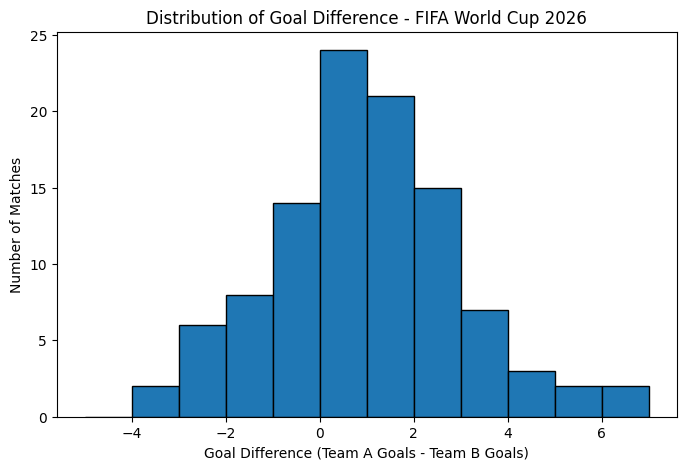

In [ ]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

plt.hist(
    matches_df["GoalDifference"],
    bins=range(
        int(matches_df["GoalDifference"].min()) - 1,
        int(matches_df["GoalDifference"].max()) + 2
    ),
    edgecolor="black"
)

plt.xlabel(
    "Goal Difference "
    "(Team A Goals - Team B Goals)"
)

plt.ylabel("Number of Matches")

plt.title("Distribution of Goal Difference - FIFA World Cup 2026")

plt.show()

### Interpretation

The goal-difference distribution is reasonably balanced, with most matches concentrated close to zero.

Most matches have a relatively small goal difference, while large winning margins occur less frequently.

There is no obvious severe skew in the distribution.

## Checking the Base Dataset

The match dataset is checked for obvious data-quality problems.

The following checks are performed:

- number of match records
- number of unique match IDs
- duplicate match IDs
- missing match dates
- missing team names
- missing scores

**Tutorials:**

- [pandas: Working with missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html)
- [pandas.DataFrame.duplicated](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html)

In [ ]:
# Missing-data reference:
# pandas development team (n.d.-c)

# Duplicate-data reference:
# pandas development team (n.d.-d)

print("Total match records:", len(matches_df))
print("Unique Match IDs:", matches_df["MatchID"].nunique())
print("Duplicate Match IDs:", matches_df["MatchID"].duplicated().sum())
print("\nMissing values:")
print(
    matches_df[
        [
            "MatchID",
            "MatchDate",
            "TeamA",
            "TeamB",
            "TeamAGoals",
            "TeamBGoals"
        ]
    ].isna().sum()
)

Total match records: 104
Unique Match IDs: 104
Duplicate Match IDs: 0

Missing values:
MatchID       0
MatchDate     0
TeamA         0
TeamB         0
TeamAGoals    0
TeamBGoals    0
dtype: int64


In [ ]:
matches_df = (matches_df.sort_values(["MatchDate", "MatchID"]).reset_index(drop=True))
matches_df.to_csv("02_world_cup_104_matches.csv", index=False)

print("Saved: 02_world_cup_104_matches.csv")

Saved: 02_world_cup_104_matches.csv


## Definition of Prior-Match Data

Prior-match data means information that was available before the kickoff of the particular World Cup match being predicted.

The definition is based on time rather than calendar year.

For example, if a World Cup match was played on 25 June 2026:

- a match played in December 2025 is prior-match information
- a match played on 5 June 2026 is prior-match information
- an earlier World Cup match played on 18 June 2026 is also prior-match information
- a match played on 28 June 2026 is not prior-match information

This rolling definition prevents future information from being used to predict an earlier match.

## Measuring Recent Team Form

Recent form will be measured using each team's five most recent international matches before the World Cup match being predicted.

A five-match window was selected because it provides a recent view of performance.

## Identifying the World Cup Teams

The 104-match dataset contains each participating team as either Team A or Team B.

The two team columns are combined to create one list of unique World Cup teams.

**Tutorials:**

- [pandas: How to combine data from multiple tables](https://pandas.pydata.org/docs/getting_started/intro_tutorials/08_combine_dataframes.html)
- [pandas.concat](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
- [pandas.DataFrame.drop_duplicates](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html)

In [ ]:
# Combining-data reference:
# pandas development team (n.d.-e)

team_a = (matches_df[["TeamAID", "TeamA"]].rename(columns={"TeamAID": "TeamID", "TeamA": "Team"}))
team_b = (matches_df[["TeamBID", "TeamB"]].rename(columns={"TeamBID": "TeamID", "TeamB": "Team"}))
world_cup_teams = (
    pd.concat([team_a, team_b], ignore_index=True)
    .drop_duplicates(subset="TeamID")
    .sort_values("Team")
    .reset_index(drop=True)
)

print("Number of World Cup teams:", len(world_cup_teams))

display(world_cup_teams)

Number of World Cup teams: 48


,TeamID,Team
0,43843,Algeria
1,43922,Argentina
2,43976,Australia
3,43934,Austria
4,43935,Belgium
5,44037,Bosnia and Herzegovina
6,43924,Brazil
7,43850,Cabo Verde
8,43899,Canada
9,43926,Colombia


## Collecting Prior International Match Data

FIFA's International Match Archive is queried using each team's FIFA ID for matches from 2025 and 2026.

The same international match may be returned when searching for both participating teams, duplicate match records will later be removed.

**Tutorials:**

- [Playwright Page.evaluate](https://playwright.dev/python/docs/api/class-page#page-evaluate)
- [MDN: Using the Fetch API](https://developer.mozilla.org/en-US/docs/Web/API/Fetch_API/Using_Fetch)
- [Python asyncio](https://docs.python.org/3/library/asyncio.html)

In [ ]:
# Browser and fetch references:
# Microsoft (n.d.-b); Mozilla (n.d.)

async def get_prior_matches():

    all_matches = []

    async with async_playwright() as p:

        browser = await p.chromium.launch(
            executable_path="/usr/bin/google-chrome",
            headless=True,
            args=["--no-sandbox", "--disable-dev-shm-usage"]
        )

        context = await browser.new_context(locale="en-AU")
        page = await context.new_page()

        # Open FIFA first to establish a browser session.
        await page.goto(
            "https://inside.fifa.com/data-centre/matches",
            wait_until="domcontentloaded",
            timeout=120000
        )

        await page.wait_for_timeout(5000)

        # Retrieve recent matches for each World Cup team.
        for _, team_row in world_cup_teams.iterrows():

            team_id = str(team_row["TeamID"])

            team_name = (team_row["Team"])

            print(f"Retrieving: {team_name}")

            for year in [2025, 2026]:

                url = (f"https://inside.fifa.com/api/data-centre/matches?gender=1&language=en&count=100&teamId={team_id}&year={year}")

                response = await page.evaluate(
                    """
                    async (url) => {

                        const response =
                            await fetch(url);

                        return {
                            status:
                                response.status,
                            body:
                                await response.json()
                        };
                    }
                    """,
                    url
                )

                if response["status"] != 200:
                    raise RuntimeWarning(f"Warning with HTTP status {response['status']} for {team_name} ({year})")
                    continue

                team_matches = (response["body"])

                # Add information showing which team caused the record to be retrieved.
                for match in team_matches:
                    match[ "_RequestedTeam"] = team_name
                    match["_RequestedTeamID"] = team_id

                all_matches.extend( team_matches)

        await browser.close()

    return all_matches


loop = asyncio.get_event_loop()
prior_matches_raw = (loop.run_until_complete(get_prior_matches()))

print("\nRaw records retrieved:", len(prior_matches_raw))

Retrieving: Algeria
Retrieving: Argentina
Retrieving: Australia
Retrieving: Austria
Retrieving: Belgium
Retrieving: Bosnia and Herzegovina
Retrieving: Brazil
Retrieving: Cabo Verde
Retrieving: Canada
Retrieving: Colombia
Retrieving: Congo DR
Retrieving: Croatia
Retrieving: Curaçao
Retrieving: Czechia
Retrieving: Côte d'Ivoire
Retrieving: Ecuador
Retrieving: Egypt
Retrieving: England
Retrieving: France
Retrieving: Germany
Retrieving: Ghana
Retrieving: Haiti
Retrieving: IR Iran
Retrieving: Iraq
Retrieving: Japan
Retrieving: Jordan
Retrieving: Korea Republic
Retrieving: Mexico
Retrieving: Morocco
Retrieving: Netherlands
Retrieving: New Zealand
Retrieving: Norway
Retrieving: Panama
Retrieving: Paraguay
Retrieving: Portugal
Retrieving: Qatar
Retrieving: Saudi Arabia
Retrieving: Scotland
Retrieving: Senegal
Retrieving: South Africa
Retrieving: Spain
Retrieving: Sweden
Retrieving: Switzerland
Retrieving: Tunisia
Retrieving: Türkiye
Retrieving: USA
Retrieving: Uruguay
Retrieving: Uzbekistan

R

In [ ]:
# Saving the raw prior-match data
with open("03_fifa_prior_matches_raw.json", "w", encoding="utf-8") as file:
  json.dump(prior_matches_raw, file, ensure_ascii=False, indent=2)

print("Saved: 03_fifa_prior_matches_raw.json")

Saved: 03_fifa_prior_matches_raw.json


## Inspecting a Prior-Match Record

This confirms that the required information is available

**Tutorial:**

- [Python json — JSON encoder and decoder](https://docs.python.org/3/library/json.html)

In [ ]:
print(json.dumps(prior_matches_raw[0], indent=2)[:5000])

{
  "idMatch": "dyvpkmkmat1c94wl4y6kyknis",
  "idMatchIfes": "147516",
  "idCompetition": "400132623",
  "idSeason": "1z35p4iuhfxxdfaqjwzkqn2fo",
  "idStage": "207mir3y73ql1144i13i8xe6s",
  "competitionName": [
    {
      "locale": "en-GB",
      "description": "Continental Final"
    }
  ],
  "seasonName": [
    {
      "locale": "en-GB",
      "description": "Africa Cup of Nations 2025"
    }
  ],
  "stageName": [
    {
      "locale": "en-GB",
      "description": "First stage"
    }
  ],
  "matchDate": "2025-12-31",
  "teamAId": "43856",
  "teamBId": "43843",
  "teamAName": [
    {
      "locale": "en-GB",
      "description": "Equatorial Guinea"
    }
  ],
  "teamBName": [
    {
      "locale": "en-GB",
      "description": "Algeria"
    }
  ],
  "teamACountryCode": "EQG",
  "teamBCountryCode": "ALG",
  "teamAFlagUrl": "https://api.fifa.com/api/v3/picture/flags-sq-2/EQG",
  "teamBFlagUrl": "https://api.fifa.com/api/v3/picture/flags-sq-2/ALG",
  "teamAScore": 1,
  "teamBScore": 3,

## Creating the Prior-Match Dataset

Only the fields needed for recent-form calculations are retained:

- match ID
- match date
- Team A and Team B IDs
- Team A and Team B names
- goals scored by each team
- competition name

Because the same match can be returned when searching for both participating teams, duplicate match IDs are removed.

**Tutorials:**

- [pandas: Intro to data structures](https://pandas.pydata.org/docs/user_guide/dsintro.html)
- [pandas.DataFrame.drop_duplicates](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html)
- [pandas.to_datetime](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html)

In [ ]:
prior_match_rows = []

for match in prior_matches_raw:

    prior_match_rows.append({
        "MatchID": match.get("idMatchIfes"),
        "MatchDate": match.get("matchDate"),
        "TeamAID": match.get("teamAId"),
        "TeamA": get_english_name(match.get("teamAName")),
        "TeamBID": match.get("teamBId"),
        "TeamB": get_english_name(match.get("teamBName")),
        "TeamAGoals": match.get("teamAScore"),
        "TeamBGoals": match.get("teamBScore"),
        "Competition": get_english_name(match.get("competitionName"))
    })

prior_matches_df = pd.DataFrame(prior_match_rows)

# Convert the FIFA date text into pandas datetime values.
prior_matches_df["MatchDate"] = pd.to_datetime(prior_matches_df["MatchDate"])

# Remove duplicate matches that were returned while searching for more than one team.
prior_matches_df = (
    prior_matches_df
    .drop_duplicates(subset="MatchID")
    .sort_values("MatchDate")
    .reset_index(drop=True)
)

display(prior_matches_df.head(10))

,MatchID,MatchDate,TeamAID,TeamA,TeamBID,TeamB,TeamAGoals,TeamBGoals,Competition
0,145687,2025-01-18,43921,USA,43931,Venezuela,3,1,Friendly
1,146260,2025-01-22,43921,USA,43901,Costa Rica,3,0,Friendly
2,146983,2025-02-08,43925,Chile,43914,Panama,6,1,Friendly
3,147253,2025-03-02,43883,South Africa,43855,Egypt,1,1,Friendly
4,147256,2025-03-09,43855,Egypt,43883,South Africa,1,3,Friendly
5,147337,2025-03-19,43865,Liberia,43888,Tunisia,0,1,FIFA World Cup™ Qualifiers
6,145704,2025-03-20,43934,Austria,1902465,Serbia,1,1,Nations League
7,145703,2025-03-20,43973,Ukraine,43935,Belgium,3,1,Nations League
8,145695,2025-03-20,43938,Croatia,43946,France,2,0,Nations League
9,147318,2025-03-20,43850,Cabo Verde,43871,Mauritius,1,0,FIFA World Cup™ Qualifiers


## Checking the Prior-Match Dataset

The checks include:

- total number of unique matches
- duplicate match IDs
- missing dates
- missing team names
- missing scores
- earliest and latest match dates

**Tutorials:**

- [pandas: Working with missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html)
- [pandas.DataFrame.duplicated](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html)

In [ ]:
print("Unique prior matches:", len(prior_matches_df))
print("Duplicate Match IDs:", prior_matches_df["MatchID"].duplicated().sum())
print("\nMissing values:")
print(
    prior_matches_df[
        [
            "MatchID",
            "MatchDate",
            "TeamAID",
            "TeamA",
            "TeamBID",
            "TeamB",
            "TeamAGoals",
            "TeamBGoals"
        ]
    ].isna().sum()
)
print("\nEarliest match:", prior_matches_df["MatchDate"].min())
print("Latest match:", prior_matches_df["MatchDate"].max())

Unique prior matches: 870
Duplicate Match IDs: 0

Missing values:
MatchID       0
MatchDate     0
TeamAID       0
TeamA         0
TeamBID       0
TeamB         0
TeamAGoals    0
TeamBGoals    0
dtype: int64

Earliest match: 2025-01-18 00:00:00
Latest match: 2026-10-07 00:00:00


In [ ]:
# Reshaping matches to the team perspective
team_a_history = pd.DataFrame({
    "MatchID": prior_matches_df["MatchID"],
    "MatchDate": prior_matches_df["MatchDate"],
    "TeamID": prior_matches_df["TeamAID"],
    "Team": prior_matches_df["TeamA"],
    "OpponentID": prior_matches_df["TeamBID"],
    "Opponent": prior_matches_df["TeamB"],
    "GoalsFor": prior_matches_df["TeamAGoals"],
    "GoalsAgainst": prior_matches_df["TeamBGoals"]
})

team_b_history = pd.DataFrame({
    "MatchID": prior_matches_df["MatchID"],
    "MatchDate": prior_matches_df["MatchDate"],
    "TeamID": prior_matches_df["TeamBID"],
    "Team": prior_matches_df["TeamB"],
    "OpponentID": prior_matches_df["TeamAID"],
    "Opponent": prior_matches_df["TeamA"],
    "GoalsFor": prior_matches_df["TeamBGoals"],
    "GoalsAgainst": prior_matches_df["TeamAGoals"]
})

team_history_df = pd.concat(
    [team_a_history, team_b_history],
    ignore_index=True
)

team_history_df = team_history_df.sort_values(
    ["TeamID", "MatchDate"]
).reset_index(drop=True)

display(team_history_df.head(10))

,MatchID,MatchDate,TeamID,Team,OpponentID,Opponent,GoalsFor,GoalsAgainst
0,141557,2025-06-06,1895293,Curaçao,43917,St. Lucia,4,0
1,141575,2025-06-10,1895293,Curaçao,43908,Haiti,5,1
2,148272,2025-06-18,1895293,Curaçao,43904,El Salvador,0,0
3,148273,2025-06-21,1895293,Curaçao,43899,Canada,1,1
4,148275,2025-06-25,1895293,Curaçao,43909,Honduras,1,2
5,149692,2025-09-06,1895293,Curaçao,43920,Trinidad and Tobago,0,0
6,149694,2025-09-10,1895293,Curaçao,43898,Bermuda,3,2
7,149695,2025-10-10,1895293,Curaçao,43910,Jamaica,2,0
8,149698,2025-10-14,1895293,Curaçao,43920,Trinidad and Tobago,1,1
9,149700,2025-11-14,1895293,Curaçao,43898,Bermuda,7,0


## Creating Basic Match Outcomes

A small number of basic outcome columns are now created.

For example:

- `Win` can later be used to calculate win rate
- `Draw` can later be used to calculate draw rate
- `Loss` can later be used to calculate loss rate
- `GoalDifference` can later be averaged across previous matches

In [ ]:
team_history_df["GoalDifference"] = (team_history_df["GoalsFor"] - team_history_df["GoalsAgainst"])
team_history_df["Win"] = (team_history_df["GoalsFor"] > team_history_df["GoalsAgainst"]).astype(int)
team_history_df["Draw"] = (team_history_df["GoalsFor"] == team_history_df["GoalsAgainst"]).astype(int)
team_history_df["Loss"] = (team_history_df["GoalsFor"] < team_history_df["GoalsAgainst"]).astype(int)

display(team_history_df.head(10))

,MatchID,MatchDate,TeamID,Team,OpponentID,Opponent,GoalsFor,GoalsAgainst,GoalDifference,Win,Draw,Loss
0,141557,2025-06-06,1895293,Curaçao,43917,St. Lucia,4,0,4,1,0,0
1,141575,2025-06-10,1895293,Curaçao,43908,Haiti,5,1,4,1,0,0
2,148272,2025-06-18,1895293,Curaçao,43904,El Salvador,0,0,0,0,1,0
3,148273,2025-06-21,1895293,Curaçao,43899,Canada,1,1,0,0,1,0
4,148275,2025-06-25,1895293,Curaçao,43909,Honduras,1,2,-1,0,0,1
5,149692,2025-09-06,1895293,Curaçao,43920,Trinidad and Tobago,0,0,0,0,1,0
6,149694,2025-09-10,1895293,Curaçao,43898,Bermuda,3,2,1,1,0,0
7,149695,2025-10-10,1895293,Curaçao,43910,Jamaica,2,0,2,1,0,0
8,149698,2025-10-14,1895293,Curaçao,43920,Trinidad and Tobago,1,1,0,0,1,0
9,149700,2025-11-14,1895293,Curaçao,43898,Bermuda,7,0,7,1,0,0


## Checking Available Prior-Match History

The planned recent-form measures will use each team's five most recent matches before a World Cup match.

Before using a five-match window, the available history is checked to make sure every World Cup team has at least five earlier matches available.

This check is important because the same method should be possible for every team.

In [ ]:
world_cup_team_ids = pd.concat([
    matches_df[["TeamAID", "TeamA"]].rename(columns={"TeamAID": "TeamID", "TeamA": "Team"}),
    matches_df[["TeamBID", "TeamB"]].rename(columns={"TeamBID": "TeamID", "TeamB": "Team"})
]).drop_duplicates()

first_world_cup_match = pd.concat([
    matches_df[["TeamAID", "MatchDate"]].rename(columns={"TeamAID": "TeamID"}),
    matches_df[["TeamBID", "MatchDate"]].rename(columns={"TeamBID": "TeamID"})
]).groupby("TeamID")["MatchDate"].min()

history_counts = []

for _, team in world_cup_team_ids.iterrows():
    team_id = team["TeamID"]
    first_match_date = first_world_cup_match.loc[team_id]

    available_matches = team_history_df[
        (team_history_df["TeamID"].astype(str) == str(team_id)) &
        (team_history_df["MatchDate"] < first_match_date)
    ]

    history_counts.append({
        "Team": team["Team"],
        "AvailablePriorMatches": len(available_matches)
    })

history_counts_df = pd.DataFrame(history_counts).sort_values(
    "AvailablePriorMatches"
)

display(history_counts_df)

,Team,AvailablePriorMatches
30,Uruguay,12
3,Qatar,13
19,Argentina,13
18,Austria,13
41,Paraguay,13
12,Belgium,14
7,Australia,14
4,Brazil,14
20,Portugal,14
23,Czechia,14


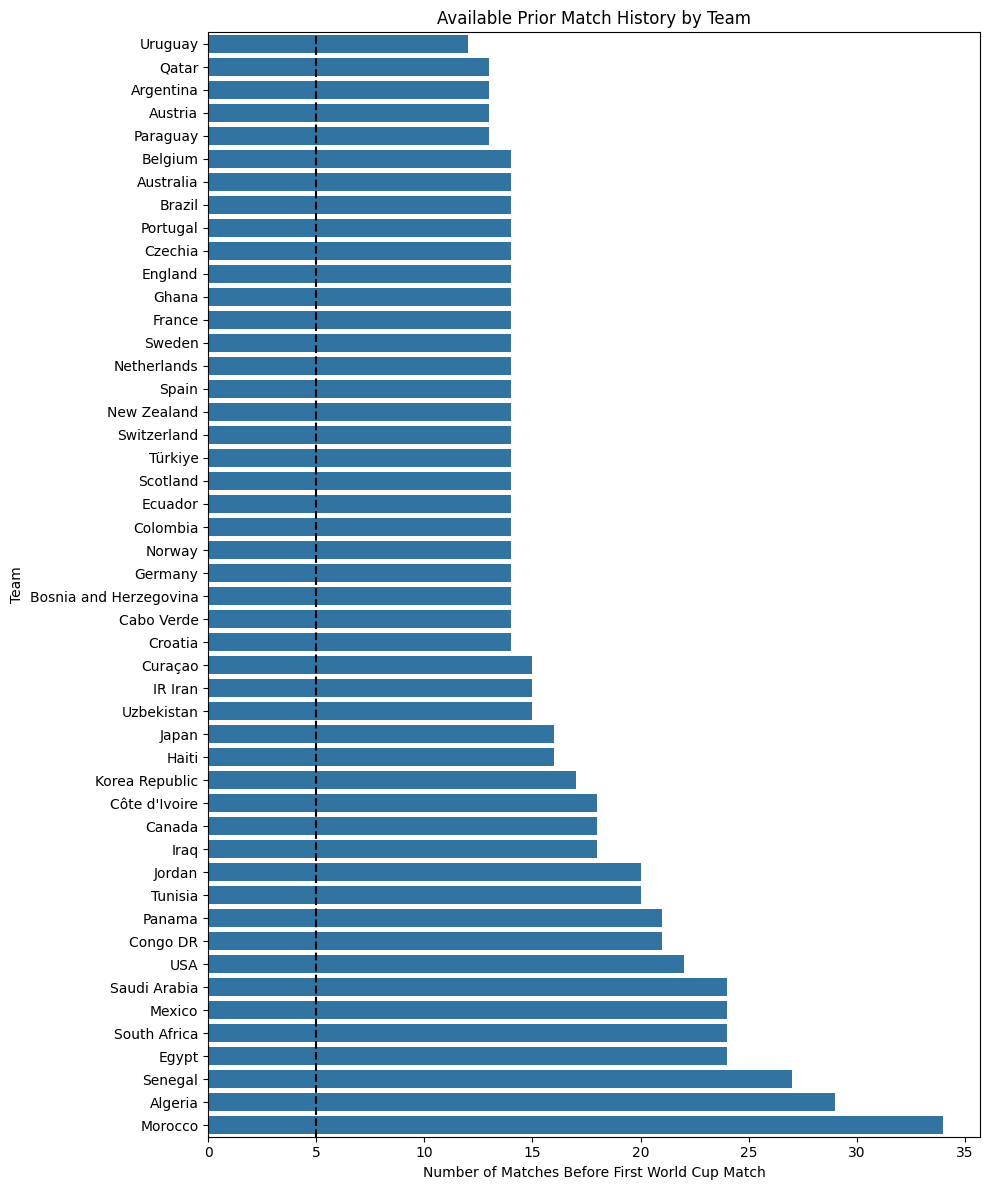

In [ ]:
plt.figure(figsize=(10, 12))
sns.barplot(
    data=history_counts_df,
    x="AvailablePriorMatches",
    y="Team"
)

plt.axvline(5, color="black", linestyle="--")
plt.title("Available Prior Match History by Team")
plt.xlabel("Number of Matches Before First World Cup Match")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

### Interpretation

All World Cup teams have more than five prior matches available before their first tournament match.

## Creating a Pool of Candidate Pre-Match Variables

Each candidate variable is calculated from a team's five most recent matches before the target World Cup match.

Several reasonable pre-match measures are created so they can later be compared using exploratory analysis.

The candidate variables include measures of:

- recent results
- attacking performance
- defensive performance
- scoring consistency
- defensive consistency
- recovery time

In [ ]:
def get_previous_five_features(team_id, target_date, history_df):
    previous_matches = (
        history_df[
            (history_df["TeamID"].astype(str) == str(team_id)) &
            (history_df["MatchDate"] < target_date)
        ]
        .sort_values("MatchDate")
    )

    last_five = previous_matches.tail(5)

    if len(last_five) < 5:
        return None

    most_recent_match_date = last_five["MatchDate"].max()

    return {
        "WinRate": last_five["Win"].mean(),
        "LossRate": last_five["Loss"].mean(),
        "DrawRate": last_five["Draw"].mean(),
        "AvgGoalsScored": last_five["GoalsFor"].mean(),
        "AvgGoalsConceded": last_five["GoalsAgainst"].mean(),
        "AvgGoalDifference": last_five["GoalDifference"].mean(),
        "CleanSheetRate": (last_five["GoalsAgainst"] == 0).mean(),
        "ScoringRate": (last_five["GoalsFor"] > 0).mean(),
        "TwoPlusGoalsRate": (last_five["GoalsFor"] >= 2).mean(),
        "ConcedeTwoPlusRate": (last_five["GoalsAgainst"] >= 2).mean(),
        "GoalsScoredStd": last_five["GoalsFor"].std(),
        "GoalsConcededStd": last_five["GoalsAgainst"].std(),
        "DaysRest": (target_date - most_recent_match_date).days
    }

### Candidate Variables Created

The function creates the following possible pre-match measures:

- `WinRate` – proportion of the previous five matches won
- `LossRate` – proportion of the previous five matches lost
- `DrawRate` – proportion of the previous five matches drawn
- `AvgGoalsScored` – average goals scored
- `AvgGoalsConceded` – average goals conceded
- `AvgGoalDifference` – average goal difference
- `CleanSheetRate` – proportion of matches where no goal was conceded
- `ScoringRate` – proportion of matches where the team scored at least once
- `TwoPlusGoalsRate` – proportion of matches where the team scored two or more goals
- `ConcedeTwoPlusRate` – proportion of matches where the team conceded two or more goals
- `GoalsScoredStd` – variation in goals scored
- `GoalsConcededStd` – variation in goals conceded
- `DaysRest` – number of days since the team's most recent match

In [ ]:
candidate_rows = []

for _, match in matches_df.iterrows():
    team_a_features = get_previous_five_features(
        match["TeamAID"],
        match["MatchDate"],
        team_history_df
    )

    team_b_features = get_previous_five_features(
        match["TeamBID"],
        match["MatchDate"],
        team_history_df
    )

    candidate_rows.append({
        "MatchID": match["MatchID"],
        "MatchDate": match["MatchDate"],
        "TeamA": match["TeamA"],
        "TeamB": match["TeamB"],

        "TeamAWinRate": team_a_features["WinRate"],
        "TeamALossRate": team_a_features["LossRate"],
        "TeamADrawRate": team_a_features["DrawRate"],
        "TeamAAvgGoalsScored": team_a_features["AvgGoalsScored"],
        "TeamAAvgGoalsConceded": team_a_features["AvgGoalsConceded"],
        "TeamAAvgGoalDifference": team_a_features["AvgGoalDifference"],
        "TeamACleanSheetRate": team_a_features["CleanSheetRate"],
        "TeamAScoringRate": team_a_features["ScoringRate"],
        "TeamATwoPlusGoalsRate": team_a_features["TwoPlusGoalsRate"],
        "TeamAConcedeTwoPlusRate": team_a_features["ConcedeTwoPlusRate"],
        "TeamAGoalsScoredStd": team_a_features["GoalsScoredStd"],
        "TeamAGoalsConcededStd": team_a_features["GoalsConcededStd"],
        "TeamADaysRest": team_a_features["DaysRest"],

        "TeamBWinRate": team_b_features["WinRate"],
        "TeamBLossRate": team_b_features["LossRate"],
        "TeamBDrawRate": team_b_features["DrawRate"],
        "TeamBAvgGoalsScored": team_b_features["AvgGoalsScored"],
        "TeamBAvgGoalsConceded": team_b_features["AvgGoalsConceded"],
        "TeamBAvgGoalDifference": team_b_features["AvgGoalDifference"],
        "TeamBCleanSheetRate": team_b_features["CleanSheetRate"],
        "TeamBScoringRate": team_b_features["ScoringRate"],
        "TeamBTwoPlusGoalsRate": team_b_features["TwoPlusGoalsRate"],
        "TeamBConcedeTwoPlusRate": team_b_features["ConcedeTwoPlusRate"],
        "TeamBGoalsScoredStd": team_b_features["GoalsScoredStd"],
        "TeamBGoalsConcededStd": team_b_features["GoalsConcededStd"],
        "TeamBDaysRest": team_b_features["DaysRest"]
    })

candidate_form_df = pd.DataFrame(candidate_rows)

display(candidate_form_df.head(10))

,MatchID,MatchDate,TeamA,TeamB,TeamAWinRate,TeamALossRate,TeamADrawRate,TeamAAvgGoalsScored,TeamAAvgGoalsConceded,TeamAAvgGoalDifference,TeamACleanSheetRate,TeamAScoringRate,TeamATwoPlusGoalsRate,TeamAConcedeTwoPlusRate,TeamAGoalsScoredStd,TeamAGoalsConcededStd,TeamADaysRest,TeamBWinRate,TeamBLossRate,TeamBDrawRate,TeamBAvgGoalsScored,TeamBAvgGoalsConceded,TeamBAvgGoalDifference,TeamBCleanSheetRate,TeamBScoringRate,TeamBTwoPlusGoalsRate,TeamBConcedeTwoPlusRate,TeamBGoalsScoredStd,TeamBGoalsConcededStd,TeamBDaysRest
0,151600,2026-06-11,Mexico,South Africa,0.6,0.0,0.4,1.8,0.4,1.4,0.6,0.8,0.4,0.0,1.923538,0.547723,6,0.2,0.4,0.4,1.2,1.4,-0.2,0.2,0.8,0.2,0.6,1.095445,0.894427,13
1,151608,2026-06-12,Korea Republic,Czechia,0.6,0.4,0.0,1.4,1.0,0.4,0.6,0.6,0.2,0.2,2.073644,1.732051,8,0.6,0.0,0.4,3.0,1.2,1.8,0.2,1.0,1.0,0.4,1.732051,0.836660,7
2,151614,2026-06-12,Canada,Bosnia and Herzegovina,0.4,0.0,0.6,1.4,0.6,0.8,0.6,0.8,0.6,0.2,0.894427,0.894427,7,0.0,0.0,1.0,0.8,0.8,0.0,0.2,0.8,0.0,0.0,0.447214,0.447214,6
3,151613,2026-06-13,Qatar,Switzerland,0.0,0.6,0.4,0.2,1.2,-1.0,0.2,0.2,0.0,0.2,0.447214,1.095445,7,0.2,0.2,0.6,1.8,1.4,0.4,0.2,0.8,0.4,0.2,1.643168,1.516575,7
4,151620,2026-06-13,Brazil,Morocco,0.6,0.2,0.2,2.6,1.4,1.2,0.0,1.0,0.6,0.4,2.073644,0.547723,7,0.6,0.0,0.4,2.2,0.6,1.6,0.4,1.0,0.6,0.0,1.303840,0.547723,6
5,151625,2026-06-13,USA,Paraguay,0.4,0.6,0.0,2.2,2.4,-0.2,0.0,0.8,0.6,0.8,1.923538,1.516575,7,0.6,0.4,0.0,1.8,1.0,0.8,0.4,1.0,0.4,0.4,1.303840,1.000000,8
6,151619,2026-06-14,Haiti,Scotland,0.4,0.4,0.2,1.6,0.8,0.8,0.4,0.8,0.4,0.2,1.516575,0.836660,8,0.6,0.4,0.0,2.4,1.0,1.4,0.2,0.6,0.6,0.2,2.190890,0.707107,8
7,151626,2026-06-14,Australia,Türkiye,0.4,0.4,0.2,1.4,1.2,0.2,0.2,0.6,0.2,0.2,2.073644,1.095445,8,0.8,0.0,0.2,2.0,0.6,1.4,0.6,1.0,0.6,0.2,1.224745,0.894427,8
8,151631,2026-06-14,Germany,Curaçao,1.0,0.0,0.0,3.6,1.0,2.6,0.4,1.0,1.0,0.2,1.673320,1.224745,8,0.2,0.6,0.2,1.2,2.2,-1.0,0.4,0.6,0.2,0.6,1.643168,2.280351,7
9,151632,2026-06-14,Côte d'Ivoire,Ecuador,0.8,0.2,0.0,2.4,0.8,1.6,0.6,1.0,0.8,0.2,1.140175,1.303840,10,0.6,0.0,0.4,1.8,0.6,1.2,0.4,1.0,0.6,0.0,0.836660,0.547723,7


## Creating Team Difference Variables

For each candidate feature, a difference is created using:

**Team A value - Team B value**

A positive value means Team A has the higher recent value.

A negative value means Team B has the higher recent value.

In [ ]:
candidate_form_df["WinRateDifference"] = (candidate_form_df["TeamAWinRate"] - candidate_form_df["TeamBWinRate"])
candidate_form_df["LossRateDifference"] = (candidate_form_df["TeamALossRate"] - candidate_form_df["TeamBLossRate"])
candidate_form_df["DrawRateDifference"] = (candidate_form_df["TeamADrawRate"] - candidate_form_df["TeamBDrawRate"])
candidate_form_df["AvgGoalsScoredDifference"] = (candidate_form_df["TeamAAvgGoalsScored"] - candidate_form_df["TeamBAvgGoalsScored"])
candidate_form_df["AvgGoalsConcededDifference"] = (candidate_form_df["TeamAAvgGoalsConceded"] - candidate_form_df["TeamBAvgGoalsConceded"])
candidate_form_df["AvgGoalDifferenceDifference"] = (candidate_form_df["TeamAAvgGoalDifference"] - candidate_form_df["TeamBAvgGoalDifference"])
candidate_form_df["CleanSheetRateDifference"] = (candidate_form_df["TeamACleanSheetRate"] - candidate_form_df["TeamBCleanSheetRate"])
candidate_form_df["ScoringRateDifference"] = (candidate_form_df["TeamAScoringRate"] - candidate_form_df["TeamBScoringRate"])
candidate_form_df["TwoPlusGoalsRateDifference"] = (candidate_form_df["TeamATwoPlusGoalsRate"] - candidate_form_df["TeamBTwoPlusGoalsRate"])
candidate_form_df["ConcedeTwoPlusRateDifference"] = (candidate_form_df["TeamAConcedeTwoPlusRate"] - candidate_form_df["TeamBConcedeTwoPlusRate"])
candidate_form_df["GoalsScoredStdDifference"] = (candidate_form_df["TeamAGoalsScoredStd"] - candidate_form_df["TeamBGoalsScoredStd"])
candidate_form_df["GoalsConcededStdDifference"] = (candidate_form_df["TeamAGoalsConcededStd"] - candidate_form_df["TeamBGoalsConcededStd"])
candidate_form_df["DaysRestDifference"] = (candidate_form_df["TeamADaysRest"] - candidate_form_df["TeamBDaysRest"])

In [ ]:
candidate_columns = [
    "WinRateDifference",
    "LossRateDifference",
    "DrawRateDifference",
    "AvgGoalsScoredDifference",
    "AvgGoalsConcededDifference",
    "AvgGoalDifferenceDifference",
    "CleanSheetRateDifference",
    "ScoringRateDifference",
    "TwoPlusGoalsRateDifference",
    "ConcedeTwoPlusRateDifference",
    "GoalsScoredStdDifference",
    "GoalsConcededStdDifference",
    "DaysRestDifference"
]

candidate_analysis_df = matches_df[
    ["MatchID", "MatchDate", "TeamA", "TeamB", "GoalDifference"]
].merge(
    candidate_form_df[["MatchID"] + candidate_columns],
    on="MatchID",
    how="left"
)

print("Rows:", len(candidate_analysis_df))
print("Candidate variables:", len(candidate_columns))
print("Missing values:", candidate_analysis_df[candidate_columns].isna().sum().sum())

display(candidate_analysis_df.head(10))

Rows: 104
Candidate variables: 13
Missing values: 0


,MatchID,MatchDate,TeamA,TeamB,GoalDifference,WinRateDifference,LossRateDifference,DrawRateDifference,AvgGoalsScoredDifference,AvgGoalsConcededDifference,AvgGoalDifferenceDifference,CleanSheetRateDifference,ScoringRateDifference,TwoPlusGoalsRateDifference,ConcedeTwoPlusRateDifference,GoalsScoredStdDifference,GoalsConcededStdDifference,DaysRestDifference
0,151600,2026-06-11,Mexico,South Africa,2,0.4,-0.4,0.0,0.6,-1.0,1.6,0.4,0.0,0.2,-0.6,0.828093,-3.467046e-01,-7
1,151608,2026-06-12,Korea Republic,Czechia,1,0.0,0.4,-0.4,-1.6,-0.2,-1.4,0.4,-0.4,-0.8,-0.2,0.341593,8.953908e-01,1
2,151614,2026-06-12,Canada,Bosnia and Herzegovina,0,0.4,0.0,-0.4,0.6,-0.2,0.8,0.4,0.0,0.6,0.2,0.447214,4.472136e-01,1
3,151613,2026-06-13,Qatar,Switzerland,0,-0.2,0.4,-0.2,-1.6,-0.2,-1.4,0.0,-0.6,-0.4,0.0,-1.195954,-4.211300e-01,0
4,151620,2026-06-13,Brazil,Morocco,0,0.0,0.2,-0.2,0.4,0.8,-0.4,-0.4,0.0,0.0,0.4,0.769804,-1.110223e-16,1
5,151625,2026-06-13,USA,Paraguay,3,-0.2,0.2,0.0,0.4,1.4,-1.0,-0.4,-0.2,0.2,0.4,0.619698,5.165751e-01,-1
6,151619,2026-06-14,Haiti,Scotland,-1,-0.2,0.0,0.2,-0.8,-0.2,-0.6,0.2,0.2,-0.2,0.0,-0.674315,1.295532e-01,0
7,151626,2026-06-14,Australia,Türkiye,2,-0.4,0.4,0.0,-0.6,0.6,-1.2,-0.4,-0.4,-0.4,0.0,0.848899,2.010179e-01,0
8,151631,2026-06-14,Germany,Curaçao,6,0.8,-0.6,-0.2,2.4,-1.2,3.6,0.0,0.4,0.8,-0.4,0.030152,-1.055606e+00,1
9,151632,2026-06-14,Côte d'Ivoire,Ecuador,1,0.2,0.2,-0.4,0.6,0.2,0.4,0.2,0.0,0.2,0.2,0.303515,7.561179e-01,3


## Comparing Candidate Variables with Goal Difference

Correlation is used to measure the strength and direction of the linear relationship between each candidate variable and Goal Difference.

A correlation closer to **1 or -1** means a stronger linear relationship.

A value close to **0** means there is little linear relationship.

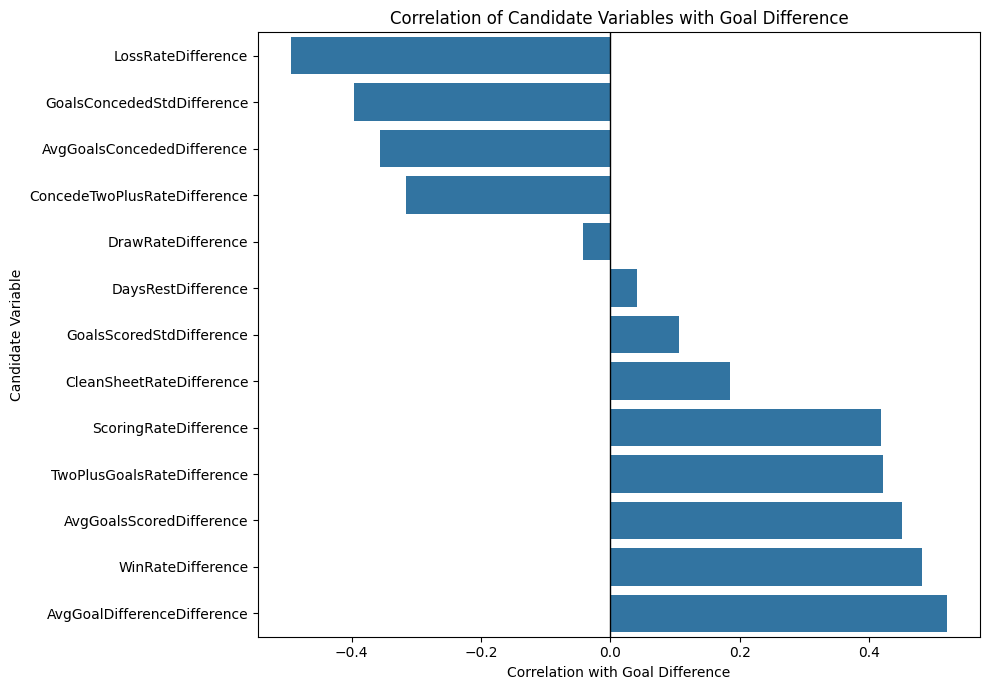

In [ ]:
candidate_correlations = (
    candidate_analysis_df[
        ["GoalDifference"] + candidate_columns
    ]
    .corr()["GoalDifference"]
    .drop("GoalDifference")
    .sort_values()
)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=candidate_correlations.values,
    y=candidate_correlations.index
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Correlation of Candidate Variables with Goal Difference")
plt.xlabel("Correlation with Goal Difference")
plt.ylabel("Candidate Variable")
plt.tight_layout()
plt.show()

### Interpretation of Candidate Correlations

The expanded candidate pool shows that some variables have a much stronger linear relationship with `GoalDifference` than others.

The strongest relationships are seen for:

- `AvgGoalDifferenceDifference`
- `LossRateDifference`
- `WinRateDifference`
- `AvgGoalsScoredDifference`
- `TwoPlusGoalsRateDifference`
- `ScoringRateDifference`
- `GoalsConcededStdDifference`
- `AvgGoalsConcededDifference`

Several variables have very weak relationships with Goal Difference, including `DaysRestDifference` and `DrawRateDifference`.

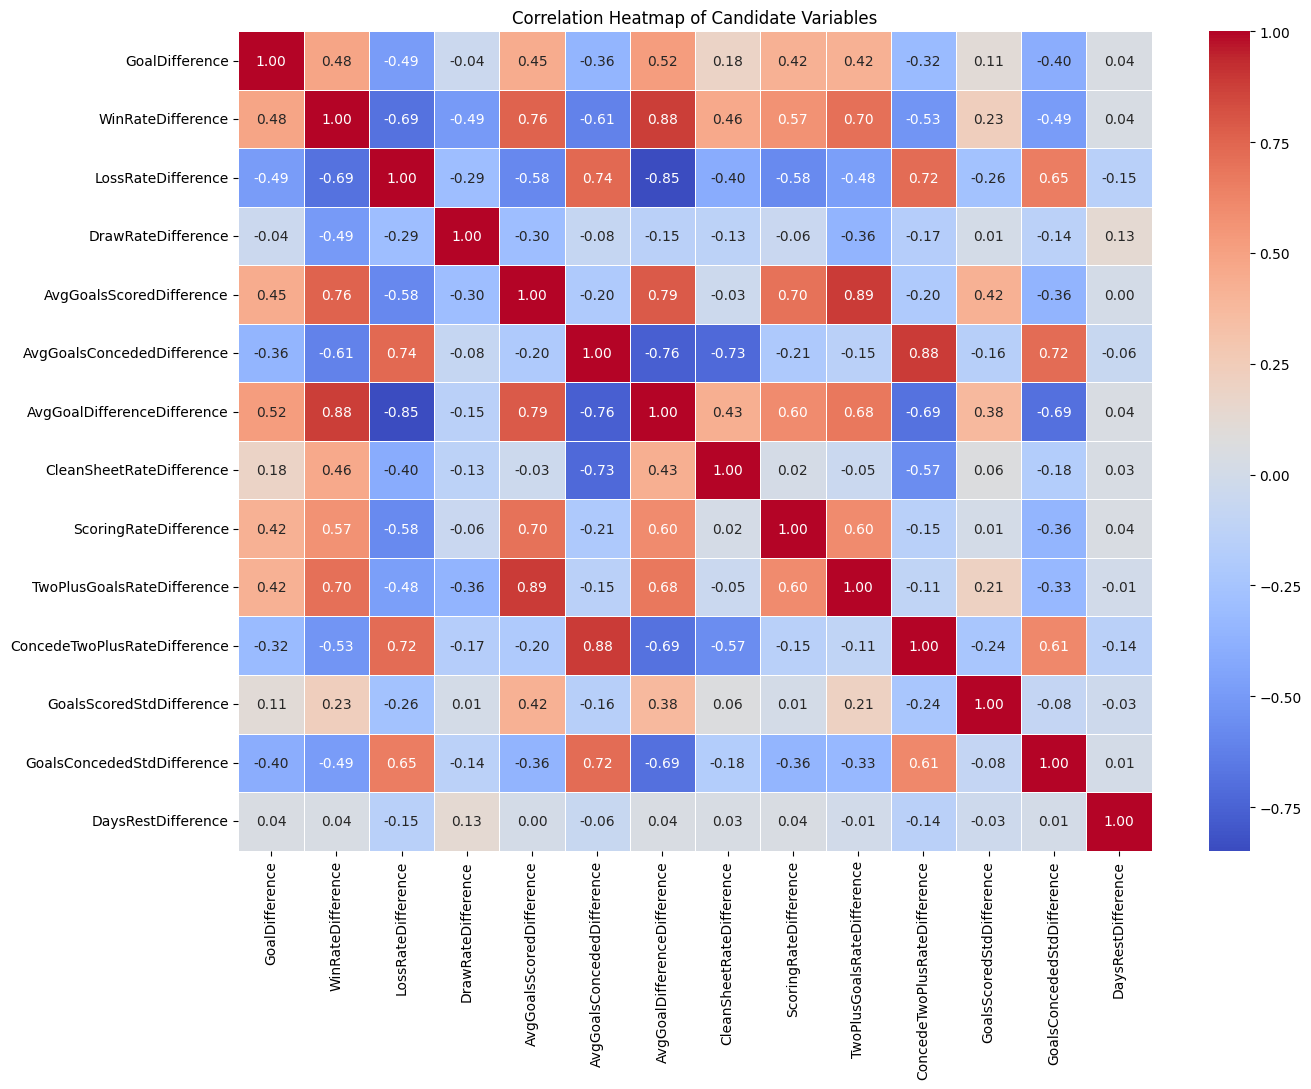

In [ ]:
# Checking overlap between candidate variables
candidate_matrix = candidate_analysis_df[
    ["GoalDifference"] + candidate_columns
].corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    candidate_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Candidate Variables")
plt.tight_layout()
plt.show()

## Selecting the Final Eight Explanatory Variables

The candidate variables were compared using both:

- their correlation with `GoalDifference`
- their correlation with each other

Two important mathematical relationships were identified:

- `AvgGoalDifference = AvgGoalsScored - AvgGoalsConceded`
- `DrawRate = 1 - WinRate - LossRate`

Because of this, including all variables from either relationship would repeat the same information.

The heatmap also showed several very strong correlations between candidates:

- `AvgGoalsScoredDifference` and `TwoPlusGoalsRateDifference`: **0.89**
- `AvgGoalsConcededDifference` and `ConcedeTwoPlusRateDifference`: **0.88**
- `WinRateDifference` and `AvgGoalDifferenceDifference`: **0.88**
- `LossRateDifference` and `AvgGoalDifferenceDifference`: **-0.85**

To reduce this overlap, the more direct and interpretable variables are preferred.

### Final Variable Selection

Five candidate variables were removed before modelling.

`AvgGoalDifferenceDifference` was removed because it is calculated directly from average goals scored and average goals conceded.

`DrawRateDifference` was removed because win, draw and loss rates are mathematically connected. If win rate and loss rate are already known, draw rate does not provide fully separate information.

`TwoPlusGoalsRateDifference` was removed because it had a very high correlation of **0.89** with `AvgGoalsScoredDifference`. Average goals scored had a slightly stronger relationship with Goal Difference and was therefore retained.

`ConcedeTwoPlusRateDifference` was removed because it had a very high correlation of **0.88** with `AvgGoalsConcededDifference`.

`DaysRestDifference` was removed because its correlation with Goal Difference was only about **0.04**, suggesting very little linear relationship in this dataset.

The final eight explanatory variables are:

1. `WinRateDifference`
2. `LossRateDifference`
3. `AvgGoalsScoredDifference`
4. `AvgGoalsConcededDifference`
5. `CleanSheetRateDifference`
6. `ScoringRateDifference`
7. `GoalsScoredStdDifference`
8. `GoalsConcededStdDifference`

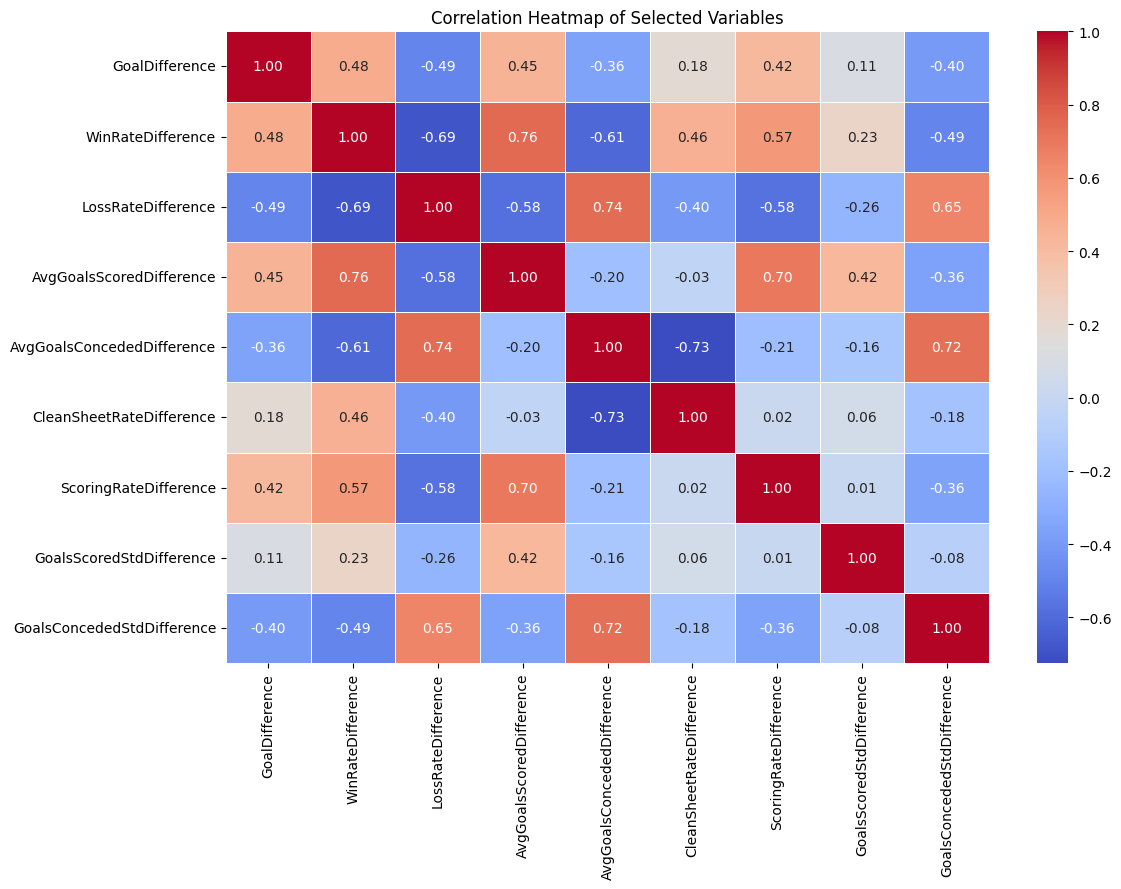

In [ ]:
selected_columns = [
    "WinRateDifference",
    "LossRateDifference",
    "AvgGoalsScoredDifference",
    "AvgGoalsConcededDifference",
    "CleanSheetRateDifference",
    "ScoringRateDifference",
    "GoalsScoredStdDifference",
    "GoalsConcededStdDifference"
]

final_correlation_matrix = candidate_analysis_df[
    ["GoalDifference"] + selected_columns
].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    final_correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Selected Variables")
plt.tight_layout()
plt.show()

## Creating the Final Regression 2.1 Dataset

The candidate analysis is complete and eight explanatory variables have been selected.

The final dataset now contains:

- 104 World Cup matches
- `GoalDifference` as the response variable
- exactly eight explanatory variables

This final dataset will be used to build and evaluate Regression 2.1.

In [ ]:
regression_2_1_df = candidate_analysis_df[
    [
        "MatchID",
        "MatchDate",
        "TeamA",
        "TeamB",
        "GoalDifference"
    ] + selected_columns
].copy()

print("Rows:", len(regression_2_1_df))
print("Explanatory variables:", len(selected_columns))
print("Missing values:", regression_2_1_df[selected_columns].isna().sum().sum())

display(regression_2_1_df.head(10))

Rows: 104
Explanatory variables: 8
Missing values: 0


,MatchID,MatchDate,TeamA,TeamB,GoalDifference,WinRateDifference,LossRateDifference,AvgGoalsScoredDifference,AvgGoalsConcededDifference,CleanSheetRateDifference,ScoringRateDifference,GoalsScoredStdDifference,GoalsConcededStdDifference
0,151600,2026-06-11,Mexico,South Africa,2,0.4,-0.4,0.6,-1.0,0.4,0.0,0.828093,-3.467046e-01
1,151608,2026-06-12,Korea Republic,Czechia,1,0.0,0.4,-1.6,-0.2,0.4,-0.4,0.341593,8.953908e-01
2,151614,2026-06-12,Canada,Bosnia and Herzegovina,0,0.4,0.0,0.6,-0.2,0.4,0.0,0.447214,4.472136e-01
3,151613,2026-06-13,Qatar,Switzerland,0,-0.2,0.4,-1.6,-0.2,0.0,-0.6,-1.195954,-4.211300e-01
4,151620,2026-06-13,Brazil,Morocco,0,0.0,0.2,0.4,0.8,-0.4,0.0,0.769804,-1.110223e-16
5,151625,2026-06-13,USA,Paraguay,3,-0.2,0.2,0.4,1.4,-0.4,-0.2,0.619698,5.165751e-01
6,151619,2026-06-14,Haiti,Scotland,-1,-0.2,0.0,-0.8,-0.2,0.2,0.2,-0.674315,1.295532e-01
7,151626,2026-06-14,Australia,Türkiye,2,-0.4,0.4,-0.6,0.6,-0.4,-0.4,0.848899,2.010179e-01
8,151631,2026-06-14,Germany,Curaçao,6,0.8,-0.6,2.4,-1.2,0.0,0.4,0.030152,-1.055606e+00
9,151632,2026-06-14,Côte d'Ivoire,Ecuador,1,0.2,0.2,0.6,0.2,0.2,0.0,0.303515,7.561179e-01


## Descriptive Statistics of the Final Variables

Descriptive statistics are used to check the range and spread of the response variable and the eight selected explanatory variables before modelling.

This helps identify unusual values and gives an overview of the final regression dataset.

In [ ]:
model_columns = ["GoalDifference"] + selected_columns

display(regression_2_1_df[model_columns].describe())

,GoalDifference,WinRateDifference,LossRateDifference,AvgGoalsScoredDifference,AvgGoalsConcededDifference,CleanSheetRateDifference,ScoringRateDifference,GoalsScoredStdDifference,GoalsConcededStdDifference
count,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000
mean,0.480769,0.057692,-0.025000,0.140385,-0.067308,0.005769,0.017308,0.009462,-0.087111
std,2.024034,0.347723,0.316151,1.004023,0.950671,0.361718,0.278847,0.724976,0.728641
min,-4.000000,-1.000000,-0.600000,-2.200000,-2.800000,-1.000000,-0.600000,-2.212930,-2.254638
25%,-1.000000,-0.200000,-0.200000,-0.600000,-0.600000,-0.200000,-0.200000,-0.452205,-0.469155
50%,0.000000,0.000000,0.000000,0.200000,-0.200000,0.000000,0.000000,0.147034,-0.100509
75%,2.000000,0.400000,0.200000,0.800000,0.400000,0.200000,0.200000,0.464956,0.303597
max,6.000000,0.800000,0.800000,2.800000,2.600000,0.800000,0.600000,2.239357,2.220055


## Final Correlation Check

The selected variables are checked one more time before the regression model is built.

This confirms the relationship between each explanatory variable and `GoalDifference`, while also checking whether any very strong predictor-to-predictor correlations remain.

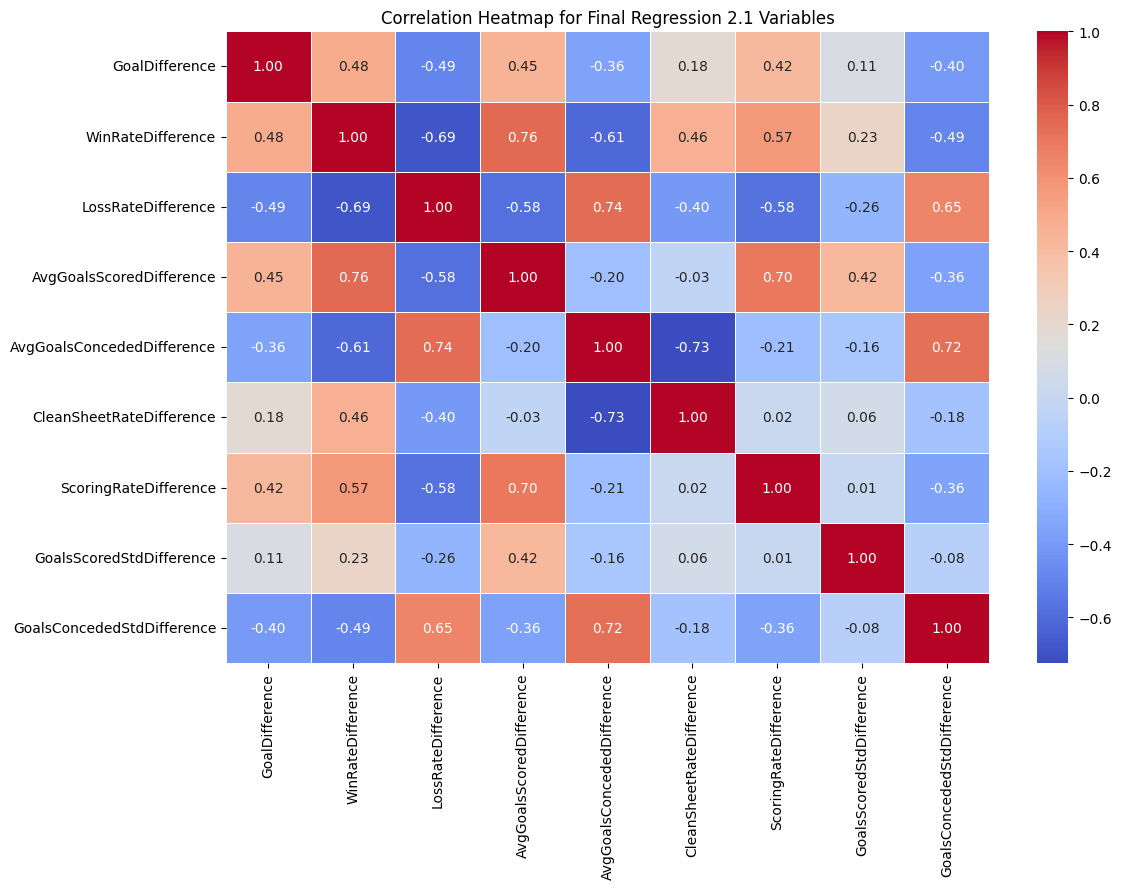

In [ ]:
correlation_matrix = regression_2_1_df[
    model_columns
].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap for Final Regression 2.1 Variables")
plt.tight_layout()
plt.show()

### Interpretation of the Final Correlation Heatmap

The final eight explanatory variables show fewer very strong correlations than the larger candidate pool.

Some moderate-to-strong relationships remain between variables. For example:

- `WinRateDifference` and `AvgGoalsScoredDifference`: **0.76**
- `LossRateDifference` and `AvgGoalsConcededDifference`: **0.74**
- `AvgGoalsConcededDifference` and `CleanSheetRateDifference`: **-0.73**

The variables measure different aspects of recent team performance and no longer include the strongest duplicate-style relationships found in the original candidate pool.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = regression_2_1_df[selected_columns]
y = regression_2_1_df["GoalDifference"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=140
)

model_2_1 = LinearRegression()
model_2_1.fit(X_train, y_train)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 83
Testing rows: 21


In [ ]:
y_pred = model_2_1.predict(X_test)

prediction_results = pd.DataFrame({
    "ActualGoalDifference": y_test,
    "PredictedGoalDifference": y_pred
})

display(prediction_results.head(10))

,ActualGoalDifference,PredictedGoalDifference
84,2,2.110085
42,1,0.888912
7,2,-1.282222
83,1,1.759258
9,1,0.008471
50,-3,-1.165423
81,2,1.092599
26,-2,-0.500252
95,1,1.550008
46,0,1.690585


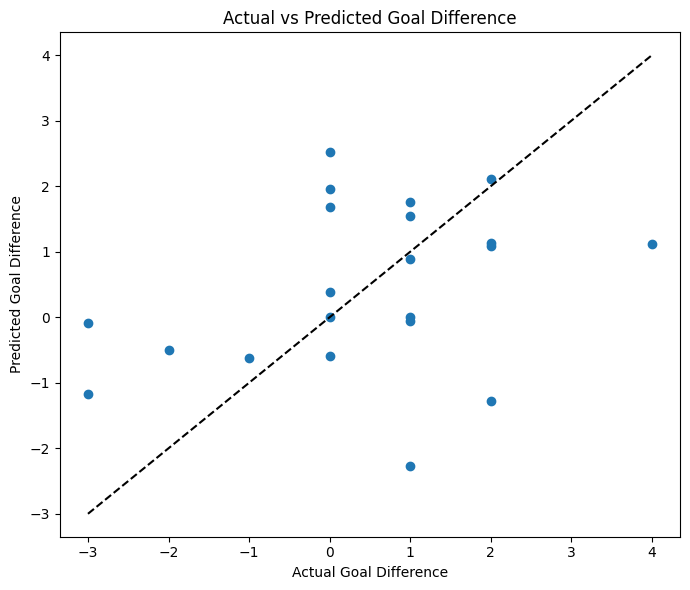

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="black"
)

plt.title("Actual vs Predicted Goal Difference")
plt.xlabel("Actual Goal Difference")
plt.ylabel("Predicted Goal Difference")
plt.tight_layout()
plt.show()

### Interpretation of Actual vs Predicted Values

The actual-versus-predicted plot shows that some predictions are reasonably close to the diagonal reference line, while others are noticeably further away.

The model performs better for some matches with smaller Goal Differences, but it has difficulty predicting more extreme results.

For example, some matches with an actual Goal Difference of around `-3` or `4` are predicted much closer to zero.

This is consistent with the model's MAE of **1.36 goals** and the variation seen in the cross-validation results.

## Evaluating the Final Model

The final model is evaluated using:

- **MAE** – the average size of the prediction error
- **RMSE** – similar to MAE, but larger errors have a bigger effect
- **R²** – shows how much of the variation in Goal Difference is explained by the model

For MAE and RMSE, smaller values are better.

For R², a higher value generally means better predictive performance.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²:", round(r2, 3))

MAE: 1.36
RMSE: 1.719
R²: -0.086


### Initial Performance of the Selected Model

The model using the eight selected explanatory variables produced:

- **MAE = 1.360**
- **RMSE = 1.719**
- **R² = -0.086**

The MAE means that the predicted Goal Difference was about **1.36 goals away from the actual result on average**.

The negative R² shows that this particular testing sample was not predicted well.

Compared with the earlier set of eight variables, MAE improved slightly, but RMSE and R² became slightly worse.

## Cross-Validation of the Selected Model

Five-fold cross-validation is used to evaluate the selected eight-variable model across different groups of matches.

This gives a better picture of model performance than relying on only one train/test split.

Both R² and MAE are calculated so that the results can also be compared with the earlier model.

In [ ]:
from sklearn.model_selection import cross_val_score

cv_r2_scores = cross_val_score(
    model_2_1,
    X,
    y,
    cv=5,
    scoring="r2"
)

cv_mae_scores = -cross_val_score(
    model_2_1,
    X,
    y,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("R² scores:", cv_r2_scores)
print("Average R²:", round(cv_r2_scores.mean(), 3))

print("\nMAE scores:", cv_mae_scores)
print("Average MAE:", round(cv_mae_scores.mean(), 3))

R² scores: [-0.05959901  0.11965206  0.31120054  0.49894936 -0.20270546]
Average R²: 0.133

MAE scores: [1.60598652 1.83722336 1.54927771 0.81354094 1.30518686]
Average MAE: 1.422


### Cross-Validation Results

The selected eight-variable model produced an average cross-validation R² of **0.133** and an average MAE of **1.422 goals**.

The positive average R² means that, overall, the model explains some of the variation in Goal Difference across the five folds.

The average MAE means that the predicted Goal Difference was about **1.42 goals away from the actual result on average**.

Performance still varied across the five folds. Three folds produced positive R² values, while two folds produced negative R² values.

This suggests that the model captures some useful information from recent team form, but its performance is not consistent across all groups of World Cup matches.

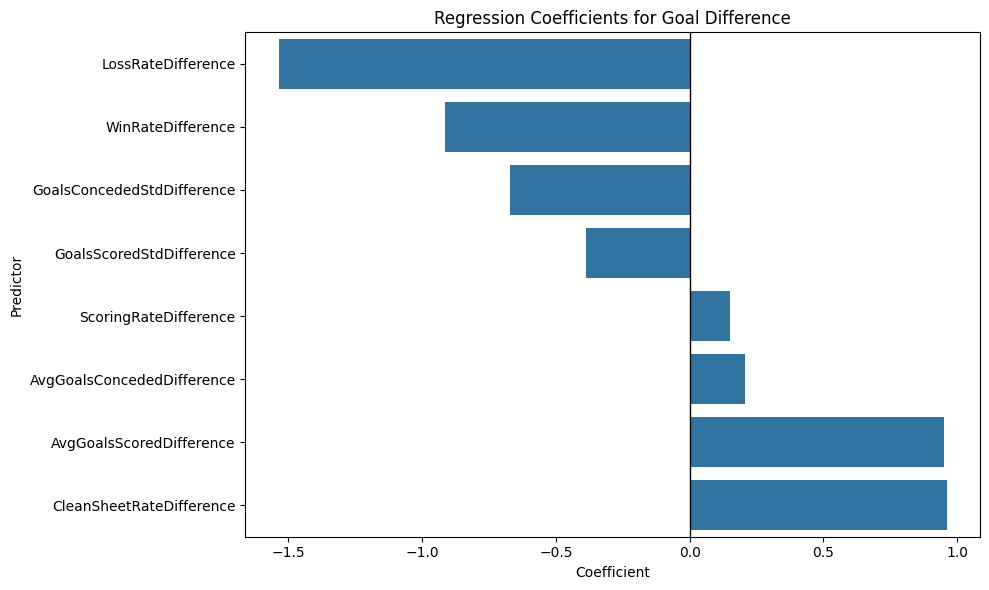

In [ ]:
coefficient_df = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model_2_1.coef_
})

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficient_df.sort_values("Coefficient"),
    x="Coefficient",
    y="Variable"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Regression Coefficients for Goal Difference")
plt.xlabel("Coefficient")
plt.ylabel("Predictor")
plt.tight_layout()
plt.show()

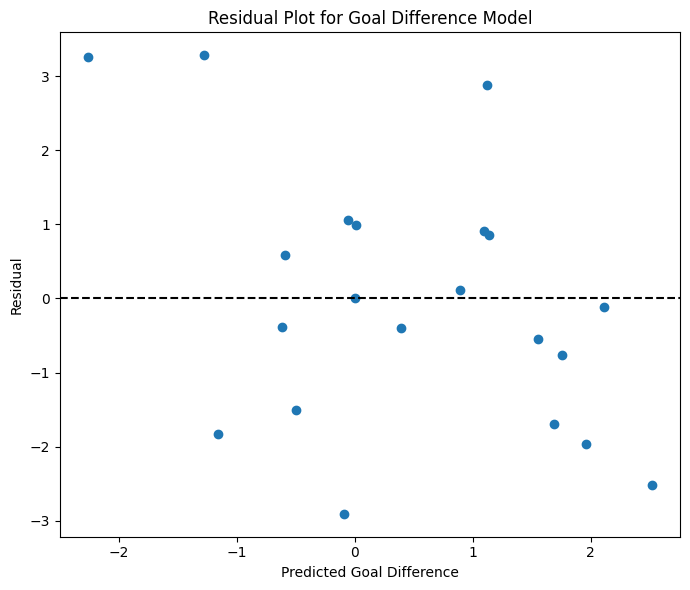

In [ ]:
# Checking prediction errors
residuals = y_test - y_pred

plt.figure(figsize=(7, 6))

plt.scatter(
    y_pred,
    residuals
)

plt.axhline(
    0,
    linestyle="--",
    color="black"
)

plt.title("Residual Plot for Goal Difference Model")
plt.xlabel("Predicted Goal Difference")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

### Interpretation of the Residual Plot

The residuals are distributed above and below zero without a clear curved pattern.

This suggests that there is no obvious systematic pattern in the prediction errors.

However, some residuals are quite large, reaching close to **3 goals** in either direction.

This shows that although the model captures some of the relationship between recent team performance and Goal Difference, it still makes substantial errors for some matches.

The residual plot therefore supports the earlier evaluation results: the model has some predictive ability, but its predictions are not consistently accurate across all matches.

## References

Charles Darwin University. (2026). *HIT140 Foundations of Data Science: Week 9 learning materials*. Charles Darwin University Learnline.

pandas Development Team. (n.d.). *pandas.DataFrame.corr*. pandas documentation.  
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html

pandas Development Team. (n.d.). *pandas.DataFrame.describe*. pandas documentation.  
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html

pandas Development Team. (n.d.). *pandas.DataFrame.merge*. pandas documentation.  
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html

Raschka, S., & Mirjalili, V. (2019). *Python machine learning* (3rd ed.). Packt Publishing.

scikit-learn developers. (n.d.). *LinearRegression*. scikit-learn.  
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

scikit-learn developers. (n.d.). *train_test_split*. scikit-learn.  
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

scikit-learn developers. (n.d.). *cross_val_score*. scikit-learn.  
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html

scikit-learn developers. (n.d.). *Regression metrics*. scikit-learn.  
https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.  
https://doi.org/10.21105/joss.03021